# Soal 4 · MASTER: Spark Structured Streaming terdistribusi lewat Kafka
**Big Data** · PC Master + 4 notebook **Soal4_Worker.ipynb** (Worker n membaca partisi n−1 topic `wiki.recentchange.raw`).

Master **memerintah** Worker lewat topic kontrol (pola `TOPIC_KONTROL` materi *Perf*), **menggabungkan** hasil jendela 1 menit
dari 4 Worker (jumlah edit dan edit bot → rasio bot), mencatat progress, lalu menganalisis.

| Sel | Isi | Soal |
|---|---|---|
| 1–3 | topic, consumer, monitor, tunggu 4 Worker | |
| 4 | fungsi skenario (MULAI/BERHENTI, sisipan data terlambat) | |
| 5 | **Fase A**: trigger 10 dtk, 5 menit (sesi baru, checkpoint dikosongkan) | 4a, 4b |
| 6 | **Fase B**: trigger 30 dtk, 5 menit (checkpoint sama) | 4b |
| 7 | **Fase C**: crash buatan Worker 1, sisipan data terlambat, berhenti 2 menit, mulai lagi | 4c |
| 8 | analisis kinerja (lastProgress) dan latensi | 4b |
| 9 | analisis offset, checkpoint, duplikat, data terlambat, **hitung ulang batch** | 4c |
| 10 | dashboard (PNG + CSV) | 4a |

**Sebelum mulai:** broker Kafka berjalan, **producer `wiki_producer_r.py` menyala** dan terus menyala sampai Sel 7 selesai.
**Urutan:** Sel 1 → 2 → 3 (tunggu 4/4) → 4 → 5 → 6 → 7 → 8 → 9 → 10.

## Sel 1. Konfigurasi dan topic

In [1]:
# ===== SEL 1: Konfigurasi dan topic =====
import os, sys, json, time, uuid, math
from pathlib import Path
from collections import Counter, defaultdict
import pandas as pd
from confluent_kafka import Producer, Consumer, KafkaError, TopicPartition
from confluent_kafka.admin import AdminClient, NewTopic

# ---------------- ISI SESUAI KELOMPOK ----------------
KELOMPOK  = "wiki4"
MASTER_IP = "192.168.1.15"
N_WORKER  = 4
DURASI_FASE   = 300          # detik per fase 4b
DURASI_C      = 180          # detik tiap putaran fase C (4c)
JEDA_BERHENTI = 120          # detik semua Worker berhenti sementara producer jalan (4c)
CRASH_WORKER  = 1            # Worker yang crash buatan di fase C
ZONA = "Asia/Jakarta"
# ------------------------------------------------------

BOOTSTRAP     = f"{MASTER_IP}:9092"
TOPIC_RAW     = "wiki.recentchange.raw"
TOPIC_KONTROL = f"{KELOMPOK}-kontrol"
TOPIC_HASIL   = f"{KELOMPOK}-hasil"
TOPIC_STATUS  = f"{KELOMPOK}-status"
RUN_ID        = uuid.uuid4().hex[:8]
LAPORAN_DIR   = Path("laporan_soal4"); LAPORAN_DIR.mkdir(exist_ok=True)

admin = AdminClient({"bootstrap.servers": BOOTSTRAP})
for nama, hasil in admin.create_topics([NewTopic(TOPIC_KONTROL, 1, 1), NewTopic(TOPIC_HASIL, 3, 1),
                                        NewTopic(TOPIC_STATUS, 3, 1)]).items():
    try:
        hasil.result(); print("Topic dibuat :", nama)
    except Exception as e:
        print("Dilewati     :", nama, "->", str(e)[:60])

def offset_raw():
    c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": f"{KELOMPOK}-intip-{uuid.uuid4().hex[:6]}"})
    hasil = {p: c.get_watermark_offsets(TopicPartition(TOPIC_RAW, p), timeout=10)[1] for p in range(N_WORKER)}
    c.close()
    return hasil

meta = admin.list_topics(timeout=10)
print(f"\n{TOPIC_RAW}: {len(meta.topics[TOPIC_RAW].partitions)} partisi (harus {N_WORKER})")
a = offset_raw(); time.sleep(10); b = offset_raw()
laju = {p: (b[p] - a[p]) / 10 for p in a}
print("Pesan masuk per detik per partisi (10 dtk):", {p: round(v, 1) for p, v in laju.items()})
if min(laju.values()) <= 0:
    raise RuntimeError("PRODUCER MATI (atau ada partisi tanpa pesan baru): nyalakan wiki_producer_r.py ke "
                       f"{BOOTSTRAP} topic {TOPIC_RAW}, lalu jalankan Sel 1 lagi.")
print("-> producer MENYALA di semua partisi")
print("RUN_ID:", RUN_ID)

Dilewati     : wiki4-kontrol -> KafkaError{code=TOPIC_ALREADY_EXISTS,val=36,str="Topic 'wiki
Dilewati     : wiki4-hasil -> KafkaError{code=TOPIC_ALREADY_EXISTS,val=36,str="Topic 'wiki
Dilewati     : wiki4-status -> KafkaError{code=TOPIC_ALREADY_EXISTS,val=36,str="Topic 'wiki

wiki.recentchange.raw: 4 partisi (harus 4)
Pesan masuk per detik per partisi (10 dtk): {0: 5.0, 1: 6.0, 2: 5.1, 3: 5.5}
-> producer MENYALA di semua partisi
RUN_ID: 5a0a353b


## Sel 2. Consumer Master, penggabungan hasil, dan monitor
Hasil jendela disimpan dengan kunci `(worker, akhir jendela, wiki)`: kiriman ulang **menimpa** dan **dihitung** sebagai duplikat.

In [2]:
# ===== SEL 2: Consumer, penggabungan, monitor =====
from IPython.display import clear_output, display

konsumen = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": f"{KELOMPOK}-master-{RUN_ID}",
                     "auto.offset.reset": "earliest", "enable.auto.commit": True})
konsumen.subscribe([TOPIC_HASIL, TOPIC_STATUS])

status, terlihat = {}, {}
jendela = {}                    # (nomor, akhir, wiki) -> rekaman pertama + jumlah kiriman
duplikat = []                   # kiriman ulang yang ditimpa
progress = {}                   # (nomor, runId, batchId, timestamp) -> rekaman
laporan_ckpt = []               # isi checkpoint setiap kali query berhenti

def sedot(detik=2.0):
    akhir_t = time.time() + detik
    while time.time() < akhir_t:
        m = konsumen.poll(0.2)
        if m is None or m.error():
            continue
        try:
            d = json.loads(m.value())
        except ValueError:
            continue
        if m.topic() == TOPIC_STATUS:
            if d.get("worker"):
                terlihat[d["worker"]] = time.time()
                if d.get("status") != "HIDUP" or d["worker"] not in status:
                    status.setdefault(d["worker"], {}).update(d)
                else:
                    status[d["worker"]].update({k: d.get(k) for k in ("aktif", "batch", "input_rps", "proses_rps", "watermark")})
            continue
        if d.get("run") != RUN_ID:
            continue
        if d["jenis"] == "jendela":
            k = (d["nomor"], d["akhir"], d["wiki"])
            if k in jendela:
                jendela[k]["kiriman"] += 1
                duplikat.append({**d, "t_terima": time.time()})
            else:
                jendela[k] = {**d, "t_terima": time.time(), "kiriman": 1}
        elif d["jenis"] == "progress":
            p = d["progress"]
            progress[(d["nomor"], p.get("runId"), p.get("batchId"), p.get("timestamp"))] = {**d, "t_terima": time.time()}
        elif d["jenis"] == "checkpoint":
            laporan_ckpt.append(d)

def gabung_jendela(tanpa_uji=True):
    """Jumlah dari 4 Worker per (jendela, wiki) -> rasio bot. Dihitung dengan Python biasa (tanpa groupby pandas)."""
    agg = {}
    for (nomor, akhir, wiki), r in list(jendela.items()):
        if tanpa_uji and wiki == "uji_terlambat":
            continue
        a = agg.setdefault((int(akhir), wiki), {"akhir": int(akhir), "wiki": wiki, "n_edit": 0, "n_bot": 0, "_w": set()})
        a["n_edit"] += int(r.get("n_edit") or 0)
        a["n_bot"] += int(r.get("n_bot") or 0)
        a["_w"].add(nomor)
    kolom = ["mulai", "akhir", "wiki", "n_edit", "n_bot", "rasio_bot", "n_worker"]
    if not agg:
        return pd.DataFrame(columns=kolom)
    baris = []
    for a in agg.values():
        mulai = pd.Timestamp(a["akhir"] - 60, unit="s", tz="UTC").tz_convert(ZONA).strftime("%Y-%m-%d %H:%M")
        baris.append({"mulai": mulai, "akhir": a["akhir"], "wiki": a["wiki"], "n_edit": a["n_edit"], "n_bot": a["n_bot"],
                      "rasio_bot": round(a["n_bot"] / a["n_edit"], 3) if a["n_edit"] else None, "n_worker": len(a["_w"])})
    return pd.DataFrame(baris, columns=kolom).sort_values(["akhir", "n_edit"], ascending=[True, False]).reset_index(drop=True)

def tampilkan(judul=""):
    aktif = {w for w, t in terlihat.items() if time.time() - t < 60 and status.get(w, {}).get("status") != "BERHENTI"}
    print("=" * 100)
    print(f"  MONITOR SOAL 4 STRUCTURED STREAMING | RUN {RUN_ID} | {judul}")
    print("=" * 100)
    print(f"Worker terhubung: {len(aktif)}/{N_WORKER} | jendela diterima: {len(jendela):,} | kiriman ganda: {len(duplikat)} "
          f"| progress: {len(progress):,} | laporan checkpoint: {len(laporan_ckpt)}")
    print(f"\n{'worker':<22}{'query':<8}{'fase':<8}{'batch':>6}{'input/s':>9}{'proses/s':>10}  watermark")
    for w in sorted(aktif):
        s = status.get(w, {})
        print(f"{w:<22}{'AKTIF' if s.get('aktif') else '-':<8}{str(s.get('fase', '-')):<8}{str(s.get('batch', '-')):>6}"
              f"{(s.get('input_rps') or 0):>9.1f}{(s.get('proses_rps') or 0):>10.1f}  {s.get('watermark') or '-'}")
    g = gabung_jendela()
    if not g.empty:
        akhir_m = g["akhir"].max()
        t = g[g["akhir"] == akhir_m].head(5)
        print(f"\nDashboard teks - jendela final terakhir {t['mulai'].iloc[0]} (gabungan {N_WORKER} Worker):")
        print(t[["wiki", "n_edit", "n_bot", "rasio_bot", "n_worker"]].to_string(index=False))

def monitor(detik=None, judul=""):
    t0 = time.time()
    try:
        while detik is None or time.time() - t0 < detik:
            sedot(2); clear_output(wait=True); tampilkan(judul)
            print(f"\n{'' if detik is None else f'sisa {detik - (time.time() - t0):.0f} dtk | '}Interrupt untuk berhenti")
    except KeyboardInterrupt:
        print("Monitor dihentikan.")

print("Consumer Master siap.")

Consumer Master siap.


## Sel 3. Tunggu 4 Worker siap
Jalankan Sel 1–5 di keempat notebook Worker (NOMOR_WORKER 1–4). Interrupt ketika **Worker terhubung = 4/4**.

In [3]:
monitor(judul='menunggu Worker')

  MONITOR SOAL 4 STRUCTURED STREAMING | RUN 5a0a353b | menunggu Worker
Worker terhubung: 4/4 | jendela diterima: 0 | kiriman ganda: 0 | progress: 0 | laporan checkpoint: 0

worker                query   fase     batch  input/s  proses/s  watermark
NthaanSnn-w1          -       C2-10s       3      0.0       0.0  -
NthaanSnn-w2          -       C2-10s       3      0.0       0.0  -
NthaanSnn-w3          -       C2-10s       3      0.0       0.0  -
NthaanSnn-w4          -       C2-10s       3      0.0       0.0  -

Interrupt untuk berhenti
Monitor dihentikan.


## Sel 4. Fungsi skenario

In [4]:
# ===== SEL 4: Perintah ke Worker dan sisipan data terlambat =====
produser = Producer({"bootstrap.servers": BOOTSTRAP, "acks": "all", "enable.idempotence": True})
LOG_SKENARIO, SISIPAN = [], []

def perintah(aksi, untuk="semua", **isi):
    produser.produce(TOPIC_KONTROL, value=json.dumps({"run": RUN_ID, "aksi": aksi, "untuk": untuk, **isi}).encode())
    produser.flush(10)
    LOG_SKENARIO.append({"waktu": time.time(), "aksi": aksi, "untuk": str(untuk), **{k: str(v) for k, v in isi.items()}})
    print(time.strftime("%H:%M:%S"), aksi, untuk, isi)

def tunggu_laporan_berhenti(sejak, n=N_WORKER, batas=90):
    t0 = time.time()
    while time.time() - t0 < batas:
        sedot(1)
        if len({d["nomor"] for d in laporan_ckpt if d["waktu"] >= sejak}) >= n:
            return True
    print("PERINGATAN: tidak semua Worker melapor berhenti")
    return False

def fase(nama, trigger, durasi, reset=False, crash_untuk=None, aksi_tengah=None):
    """MULAI semua Worker -> pantau `durasi` detik (aksi_tengah = (detik, fungsi)) -> BERHENTI."""
    a = offset_raw(); time.sleep(5); b = offset_raw()
    kosong = [p for p in a if b[p] == a[p]]
    if kosong:
        raise RuntimeError(f"Tidak ada pesan baru di partisi {kosong} selama 5 dtk: producer mati atau menulis ke broker/topic lain. "
                           f"Nyalakan producer ke {BOOTSTRAP} topic {TOPIC_RAW}, lalu jalankan sel ini lagi.")
    if crash_untuk:
        lain = [w for w in range(1, N_WORKER + 1) if w != crash_untuk]
        perintah("MULAI", untuk=lain, fase=nama, trigger=trigger, reset=reset)
        perintah("MULAI", untuk=[crash_untuk], fase=nama, trigger=trigger, reset=reset, crash=True, crash_setelah=3)
    else:
        perintah("MULAI", fase=nama, trigger=trigger, reset=reset)
    t0 = time.time(); sudah = False
    try:
        while time.time() - t0 < durasi:
            sedot(2); clear_output(wait=True); tampilkan(f"fase {nama} (trigger {trigger} dtk)")
            print(f"\nsisa {durasi - (time.time() - t0):.0f} dtk")
            if aksi_tengah and not sudah and time.time() - t0 >= aksi_tengah[0]:
                aksi_tengah[1](); sudah = True
    finally:
        t_stop = time.time()
        perintah("BERHENTI", fase=nama)
        tunggu_laporan_berhenti(t_stop)

def sisipkan_terlambat():
    """Pesan uji ke SETIAP partisi: 3 terlambat 1 menit (di dalam watermark) dan 3 terlambat 10 menit (di luar)."""
    p = Producer({"bootstrap.servers": BOOTSTRAP, "acks": "all"})
    now = time.time()
    for menit in (1, 10):
        for part in range(N_WORKER):
            for i in range(3):
                ts = int(now - menit * 60) - i
                pesan = {"id": -int(now * 100) - 1000 * menit - 10 * part - i, "type": "edit", "wiki": "uji_terlambat",
                         "server_name": "uji", "title": f"uji_{menit}m_p{part}_{i}", "namespace": 0, "user": "uji",
                         "is_anon": False, "anon_kind": None, "bot": False, "minor": False, "timestamp": ts,
                         "length_old": 100, "length_new": 110, "comment": f"sisipan terlambat {menit} menit", "ingest_ts": now}
                p.produce(TOPIC_RAW, key=f"uji_terlambat:{pesan['title']}", value=json.dumps(pesan).encode(), partition=part)
                SISIPAN.append({"partisi": part, "terlambat_menit": menit, "ts": ts, "title": pesan["title"], "dikirim": now})
    p.flush(10)
    print(f"\n>>> {len(SISIPAN)} pesan terlambat disisipkan (1 menit dan 10 menit, 3 per partisi)")

print("Fungsi skenario siap.")

Fungsi skenario siap.


## Sel 5. Fase A · trigger 10 detik (Soal 4a, 4b)
Sesi baru: checkpoint Worker dikosongkan, query mulai dari offset **latest**. Durasi `DURASI_FASE`.

In [5]:
fase('A-10s', trigger=10, durasi=DURASI_FASE, reset=True)

  MONITOR SOAL 4 STRUCTURED STREAMING | RUN 5a0a353b | fase A-10s (trigger 10 dtk)
Worker terhubung: 4/4 | jendela diterima: 465 | kiriman ganda: 0 | progress: 124 | laporan checkpoint: 0

worker                query   fase     batch  input/s  proses/s  watermark
NthaanSnn-w1          AKTIF   A-10s       29      4.1      20.4  2026-11-19T09:58:04.000Z
NthaanSnn-w2          AKTIF   A-10s       29      5.2      24.6  2026-11-19T09:58:04.000Z
NthaanSnn-w3          AKTIF   A-10s       29      7.5      33.0  2026-11-19T09:58:04.000Z
NthaanSnn-w4          AKTIF   A-10s       29      6.6      32.0  2026-11-19T09:58:04.000Z

Dashboard teks - jendela final terakhir 2026-11-19 16:57 (gabungan 4 Worker):
        wiki  n_edit  n_bot  rasio_bot  n_worker
wikidatawiki     498      3      0.006         4
 commonswiki     257    199      0.774         4
      enwiki      85      0      0.000         4
      bewiki      85     85      1.000         4
elwiktionary      74     74      1.000         4

si

## Sel 6. Fase B · trigger 30 detik (Soal 4b)
**Checkpoint sama**: query melanjutkan dari offset terakhir Fase A (batch pertama memproses data yang masuk selama jeda).

In [6]:
fase('B-30s', trigger=30, durasi=DURASI_FASE)

  MONITOR SOAL 4 STRUCTURED STREAMING | RUN 5a0a353b | fase B-30s (trigger 30 dtk)
Worker terhubung: 4/4 | jendela diterima: 1,206 | kiriman ganda: 0 | progress: 168 | laporan checkpoint: 4

worker                query   fase     batch  input/s  proses/s  watermark
NthaanSnn-w1          AKTIF   B-30s       41      4.5      55.3  2026-11-19T10:03:04.000Z
NthaanSnn-w2          AKTIF   B-30s       41      5.0      51.6  2026-11-19T10:03:04.000Z
NthaanSnn-w3          AKTIF   B-30s       41      5.9      62.3  2026-11-19T10:03:04.000Z
NthaanSnn-w4          AKTIF   B-30s       40      6.0      71.1  2026-11-19T10:02:34.000Z

Dashboard teks - jendela final terakhir 2026-11-19 17:02 (gabungan 4 Worker):
        wiki  n_edit  n_bot  rasio_bot  n_worker
wikidatawiki     520      2      0.004         4
 commonswiki     232    181      0.780         4
      enwiki      88      3      0.034         4
elwiktionary      74     74      1.000         4
      frwiki      28      4      0.143         4



## Sel 7. Fase C · restart dengan checkpoint yang sama (Soal 4c)
1. **C1** (trigger 10 dtk, `DURASI_C`): Worker `CRASH_WORKER` crash buatan; pada detik ke-90 Master menyisipkan data terlambat.
2. Semua Worker **berhenti** `JEDA_BERHENTI` detik; producer tetap mengirim.
3. **C2** (trigger 10 dtk, `DURASI_C`): semua Worker mulai lagi dengan checkpoint yang sama; Worker yang crash mengulang batch yang belum di-commit.

In [7]:
# ===== SEL 7: Fase C =====
fase("C1-10s", trigger=10, durasi=DURASI_C, crash_untuk=CRASH_WORKER, aksi_tengah=(90, sisipkan_terlambat))
print(f"\nSemua Worker berhenti {JEDA_BERHENTI} dtk; producer tetap jalan ...")
a = offset_raw(); monitor(JEDA_BERHENTI, judul="JEDA: semua query berhenti"); b = offset_raw()
JEDA_PESAN = {p: b[p] - a[p] for p in a}
print("Pesan yang menumpuk selama jeda per partisi:", JEDA_PESAN)
fase("C2-10s", trigger=10, durasi=DURASI_C)
print("Fase C selesai.")

  MONITOR SOAL 4 STRUCTURED STREAMING | RUN 5a0a353b | fase C2-10s (trigger 10 dtk)
Worker terhubung: 4/4 | jendela diterima: 2,223 | kiriman ganda: 33 | progress: 307 | laporan checkpoint: 13

worker                query   fase     batch  input/s  proses/s  watermark
NthaanSnn-w1          AKTIF   C2-10s      65      0.6       2.0  2026-11-19T10:10:03.000Z
NthaanSnn-w2          AKTIF   C2-10s      78      0.5       1.7  2026-11-19T10:10:02.000Z
NthaanSnn-w3          AKTIF   C2-10s      78      0.4       1.3  2026-11-19T10:10:03.000Z
NthaanSnn-w4          AKTIF   C2-10s      78      0.5       1.7  2026-11-19T10:10:02.000Z

Dashboard teks - jendela final terakhir 2026-11-19 17:09 (gabungan 4 Worker):
        wiki  n_edit  n_bot  rasio_bot  n_worker
wikidatawiki     512      0      0.000         4
 commonswiki     266    213      0.801         4
      enwiki      82      2      0.024         4
elwiktionary      74     74      1.000         4
      ttwiki      27     27      1.000         

## Sel 8. Soal 4b: kinerja query (lastProgress) dan latensi hasil
Batch pertama setiap run (memproses data yang menumpuk) dan batch tanpa data dipisahkan dari statistik.

--- Ringkasan per trigger (batch normal; input_rps_total = jumlah 4 Worker) ---


,n_batch,baris_per_batch,input_rps_total,proses_rps_per_worker,durasi_batch_ms,walCommit_ms,n_jendela,latensi_median_dtk,latensi_p95_dtk,latensi_maks_dtk
fase,,,,,,,,,,
A-10s,120,56.8,24.0,23.3,2342.2,305.8,465.0,132.0,132.5,132.5
B-30s,40,167.0,22.2,70.0,2412.8,321.8,741.0,152.5,152.7,152.7


--- Per Worker ---


,fase,worker,n_batch,baris_per_batch,input_rps,proses_rps,durasi_batch_ms,walCommit_ms
0,A-10s,1,30,58.5,6.2,24.4,2387.0,303.5
1,A-10s,2,30,57.0,6.2,22.9,2297.5,307.5
2,A-10s,3,30,53.5,5.7,23.8,2289.0,310.5
3,A-10s,4,30,56.5,6.0,22.5,2432.5,304.0
4,B-30s,1,10,148.5,5.1,61.6,2408.0,315.0
5,B-30s,2,10,176.5,5.8,72.6,2417.0,324.5
6,B-30s,3,10,173.5,5.6,67.6,2408.5,319.0
7,B-30s,4,10,160.5,5.7,72.6,2482.0,326.5


--- Batch pertama setiap run (memproses tumpukan) ---


,worker,fase,batchId,numInputRows,durasi_batch_ms,processedRowsPerSecond
3,1,A-10s,0,4,8395,0.5
127,1,B-30s,31,107,3216,33.3
171,1,C1-10s,42,286,1836,155.8
232,1,C2-10s,48,60,1587,37.8
2,2,A-10s,0,1,8902,0.1
125,2,B-30s,31,110,3231,34.0
168,2,C1-10s,42,243,1853,131.1
233,2,C2-10s,61,777,2019,384.7
0,3,A-10s,0,4,8620,0.5
124,3,B-30s,31,113,3117,36.2


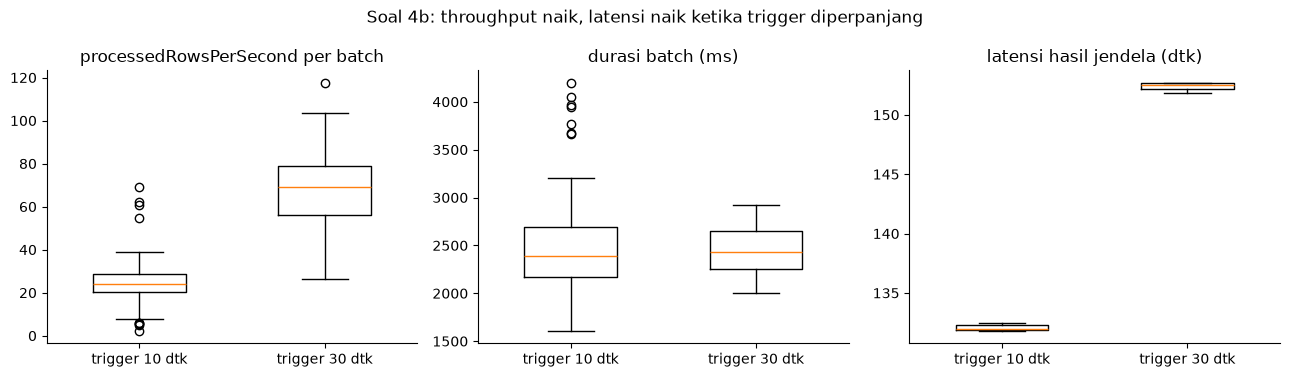

In [8]:
# ===== SEL 8: Soal 4b =====
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def baris_progress(r):
    p = r["progress"]; src = (p.get("sources") or [{}])[0]; dur = p.get("durationMs") or {}
    ops = p.get("stateOperators") or []
    def off(x):                                   # offset bisa dict, teks JSON, atau teks kosong (batch tanpa offset)
        if isinstance(x, str):
            try:
                return json.loads(x)
            except ValueError:
                return None
        return x
    return {"worker": r["nomor"], "fase": r["fase"], "runId": p.get("runId"), "batchId": p.get("batchId"),
            "waktu": pd.to_datetime(p.get("timestamp")), "numInputRows": p.get("numInputRows", 0),
            "inputRowsPerSecond": p.get("inputRowsPerSecond") or 0.0,
            "processedRowsPerSecond": p.get("processedRowsPerSecond") or 0.0,
            "durasi_batch_ms": dur.get("triggerExecution"), "addBatch_ms": dur.get("addBatch"),
            "walCommit_ms": dur.get("walCommit"), "queryPlanning_ms": dur.get("queryPlanning"),
            "latestOffset_ms": dur.get("latestOffset"), "watermark": (p.get("eventTime") or {}).get("watermark"),
            "dibuang_watermark": sum(o.get("numRowsDroppedByWatermark", 0) for o in ops),
            "state_baris": sum(o.get("numRowsTotal", 0) for o in ops),
            "startOffset": off(src.get("startOffset")), "endOffset": off(src.get("endOffset"))}

prog = pd.DataFrame([baris_progress(r) for r in progress.values()]).sort_values(["worker", "waktu"])
prog["pertama_di_run"] = prog.groupby(["worker", "runId"])["batchId"].transform("min") == prog["batchId"]
prog.drop(columns=["startOffset", "endOffset"]).to_csv(LAPORAN_DIR / "4b_progress_semua_batch.csv", index=False)

normal = prog[(~prog["pertama_di_run"]) & (prog["numInputRows"] > 0) & prog["fase"].isin(["A-10s", "B-30s"])]
per_w = (normal.groupby(["fase", "worker"])
               .agg(n_batch=("batchId", "nunique"), baris_per_batch=("numInputRows", "median"),
                    input_rps=("inputRowsPerSecond", "mean"), proses_rps=("processedRowsPerSecond", "median"),
                    durasi_batch_ms=("durasi_batch_ms", "median"), walCommit_ms=("walCommit_ms", "median"))
               .reset_index())
ring = (per_w.groupby("fase")
             .agg(n_batch=("n_batch", "sum"), baris_per_batch=("baris_per_batch", "median"),
                  input_rps_total=("input_rps", "sum"), proses_rps_per_worker=("proses_rps", "median"),
                  durasi_batch_ms=("durasi_batch_ms", "median"), walCommit_ms=("walCommit_ms", "median")).round(1))

jd = pd.DataFrame(list(jendela.values()))
jd = jd[jd["wiki"] != "uji_terlambat"].copy()
jd["latensi_dtk"] = jd["t_terima"] - jd["akhir"]
lat = jd.groupby("fase")["latensi_dtk"].describe(percentiles=[0.5, 0.95])[["count", "50%", "95%", "max"]].round(1)
ring = ring.join(lat.rename(columns={"count": "n_jendela", "50%": "latensi_median_dtk",
                                     "95%": "latensi_p95_dtk", "max": "latensi_maks_dtk"}))
ring.to_csv(LAPORAN_DIR / "4b_ringkasan_trigger.csv")
print("--- Ringkasan per trigger (batch normal; input_rps_total = jumlah 4 Worker) ---"); display(ring)
print("--- Per Worker ---"); display(per_w.round(1))
catch = prog[prog["pertama_di_run"]][["worker", "fase", "batchId", "numInputRows", "durasi_batch_ms", "processedRowsPerSecond"]]
print("--- Batch pertama setiap run (memproses tumpukan) ---"); display(catch)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, kol, judul in zip(axs, ["processedRowsPerSecond", "durasi_batch_ms", None],
                          ["processedRowsPerSecond per batch", "durasi batch (ms)", "latensi hasil jendela (dtk)"]):
    data = ([normal[normal["fase"] == f][kol].dropna() for f in ("A-10s", "B-30s")] if kol else
            [jd[jd["fase"] == f]["latensi_dtk"].dropna() for f in ("A-10s", "B-30s")])
    ax.boxplot(data, widths=0.5)                       # label diset terpisah: aman untuk semua versi matplotlib
    ax.set_xticks([1, 2]); ax.set_xticklabels(["trigger 10 dtk", "trigger 30 dtk"])
    ax.set_title(judul)
fig.suptitle("Soal 4b: throughput naik, latensi naik ketika trigger diperpanjang")
fig.tight_layout(); fig.savefig(LAPORAN_DIR / "4b_trigger.png", dpi=130); plt.show(); plt.close(fig)

## Sel 9. Soal 4c: offset, checkpoint, duplikat, data terlambat, dan bukti tidak ganda / tidak terlewat
**Bukti akhir:** untuk setiap partisi, Master membaca ulang rentang offset yang sama dengan **batch** Kafka
(dari offset awal checkpoint sampai offset batch terakhir yang di-commit) dan menghitung jendela dengan definisi yang sama.
Untuk jendela yang sudah final (akhir ≤ watermark terakhir), selisih stream vs batch harus **hanya** berasal dari data terlambat yang dibuang watermark.

In [9]:
# ===== SEL 9: Soal 4c =====
# (1) Kesinambungan offset antar-run
def offset_p(o, w):
    return (o or {}).get(TOPIC_RAW, {}).get(str(w - 1))

baris = []
for w in range(1, N_WORKER + 1):
    pw = prog[prog["worker"] == w].sort_values("waktu")
    runs = list(dict.fromkeys(pw["runId"]))
    for i in range(1, len(runs)):
        lama = pw[pw["runId"] == runs[i - 1]].iloc[-1]
        baru = pw[pw["runId"] == runs[i]].iloc[0]
        baris.append({"worker": w, "fase_lama": lama["fase"], "batch_terakhir": lama["batchId"],
                      "endOffset_lama": offset_p(lama["endOffset"], w), "fase_baru": baru["fase"],
                      "batch_pertama": baru["batchId"], "startOffset_baru": offset_p(baru["startOffset"], w),
                      "lanjut_tepat": offset_p(lama["endOffset"], w) == offset_p(baru["startOffset"], w),
                      "baris_batch_pertama": baru["numInputRows"]})
kes = pd.DataFrame(baris)
crash_fase = {(d["nomor"], d["fase"]) for d in laporan_ckpt if str(d.get("alasan", "")).startswith("query mati")}
kes["catatan"] = [f"batch {b} gagal sebelum commit -> DIULANG dari offset yang sama" if (w, f) in crash_fase
                  else "berhenti normal -> lanjut ke batch berikutnya"
                  for w, f, b in zip(kes["worker"], kes["fase_lama"], kes["batch_pertama"])]
kes.to_csv(LAPORAN_DIR / "4c_kesinambungan_offset.csv", index=False)
print("--- (1) Offset awal run baru = offset akhir run sebelumnya ---"); display(kes)

# (2) Isi checkpoint setiap kali query berhenti
ck = pd.DataFrame([{"worker": d["nomor"], "fase": d["fase"], "alasan": d["alasan"][:60],
                    "n_offsets": d["info"]["n_offsets"], "n_commits": d["info"]["n_commits"],
                    "offsets_akhir": d["info"]["offsets"][-3:], "commits_akhir": d["info"]["commits"][-3:],
                    "watermark_ms": (d["info"].get("metadata_batch_akhir") or {}).get("batchWatermarkMs")}
                   for d in laporan_ckpt])
ck.to_csv(LAPORAN_DIR / "4c_checkpoint.csv", index=False)
print("--- (2) Folder checkpoint saat query berhenti (offsets = WAL rencana batch, commits = batch selesai) ---"); display(ck)

# (3) Kiriman ganda dari batch yang diulang
dp = pd.DataFrame(duplikat)
print(f"--- (3) Kiriman ganda diterima Master: {len(dp)} (semuanya ditimpa, tidak dihitung dua kali) ---")
if not dp.empty:
    display(dp.groupby(["nomor", "batch", "fase"]).size().rename("kiriman_ganda").reset_index())
    dp.to_csv(LAPORAN_DIR / "4c_kiriman_ganda.csv", index=False)

# (4) Data terlambat
si = pd.DataFrame(SISIPAN)
uji = pd.DataFrame(list(jendela.values()))
uji = uji[uji["wiki"] == "uji_terlambat"] if not uji.empty else uji
print(f"--- (4) Data terlambat: disisipkan {len(si)} pesan; masuk hasil stream: "
      f"{int(uji['n_edit'].sum()) if not uji.empty else 0}; "
      f"baris dibuang watermark (progress, setelah agregasi parsial): {int(prog['dibuang_watermark'].sum())} ---")
if not si.empty:
    display(si.groupby("terlambat_menit").size().rename("disisipkan").to_frame()
              .join(pd.Series({1: int(uji["n_edit"].sum()) if not uji.empty else 0, 10: 0}, name="masuk_stream_diharapkan")))

--- (1) Offset awal run baru = offset akhir run sebelumnya ---


,worker,fase_lama,batch_terakhir,endOffset_lama,fase_baru,batch_pertama,startOffset_baru,lanjut_tepat,baris_batch_pertama,catatan
0,1,A-10s,30,None,B-30s,31,None,True,107,berhenti normal -> lanjut ke batch berikutnya
1,1,B-30s,41,None,C1-10s,42,None,True,286,berhenti normal -> lanjut ke batch berikutnya
2,1,C1-10s,47,None,C2-10s,48,None,True,60,batch 48 gagal sebelum commit -> DIULANG dari ...
3,2,A-10s,30,None,B-30s,31,None,True,110,berhenti normal -> lanjut ke batch berikutnya
4,2,B-30s,41,None,C1-10s,42,None,True,243,berhenti normal -> lanjut ke batch berikutnya
5,2,C1-10s,60,None,C2-10s,61,None,True,777,berhenti normal -> lanjut ke batch berikutnya
6,3,A-10s,30,None,B-30s,31,None,True,113,berhenti normal -> lanjut ke batch berikutnya
7,3,B-30s,41,None,C1-10s,42,None,True,223,berhenti normal -> lanjut ke batch berikutnya
8,3,C1-10s,60,None,C2-10s,61,None,True,746,berhenti normal -> lanjut ke batch berikutnya
9,4,A-10s,30,None,B-30s,31,None,True,108,berhenti normal -> lanjut ke batch berikutnya


--- (2) Folder checkpoint saat query berhenti (offsets = WAL rencana batch, commits = batch selesai) ---


,worker,fase,alasan,n_offsets,n_commits,offsets_akhir,commits_akhir,watermark_ms
0,2,A-10s,perintah Master,31,31,"[28, 29, 30]","[28, 29, 30]",1795082294000
1,3,A-10s,perintah Master,31,31,"[28, 29, 30]","[28, 29, 30]",1795082294000
2,1,A-10s,perintah Master,31,31,"[28, 29, 30]","[28, 29, 30]",1795082294000
3,4,A-10s,perintah Master,31,31,"[28, 29, 30]","[28, 29, 30]",1795082294000
4,2,B-30s,perintah Master,42,42,"[39, 40, 41]","[39, 40, 41]",1795082584000
5,4,B-30s,perintah Master,42,42,"[39, 40, 41]","[39, 40, 41]",1795082584000
6,1,B-30s,perintah Master,42,42,"[39, 40, 41]","[39, 40, 41]",1795082584000
7,3,B-30s,perintah Master,42,42,"[39, 40, 41]","[39, 40, 41]",1795082584000
8,1,C1-10s,query mati: An exception was raised by the Pyt...,49,48,"[46, 47, 48]","[45, 46, 47]",1795082704000
9,1,C1-10s,perintah Master,49,48,"[46, 47, 48]","[45, 46, 47]",1795082704000


--- (3) Kiriman ganda diterima Master: 33 (semuanya ditimpa, tidak dihitung dua kali) ---


,nomor,batch,fase,kiriman_ganda
0,1,48,C2-10s,33


--- (4) Data terlambat: disisipkan 24 pesan; masuk hasil stream: 12; baris dibuang watermark (progress, setelah agregasi parsial): 4 ---


,disisipkan,masuk_stream_diharapkan
terlambat_menit,,
1,12,12
10,12,0


In [10]:
# ===== SEL 9b: Hitung ulang batch Kafka vs hasil stream (tidak ganda, tidak terlewat) =====
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, LongType, BooleanType

spark = (SparkSession.builder.appName(f"{KELOMPOK}-master-verifikasi").master("local[2]")
         .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.1.3")
         .config("spark.driver.host", "127.0.0.1").config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.sql.session.timeZone", ZONA)
         .config("spark.pyspark.python", sys.executable).config("spark.pyspark.driver.python", sys.executable)
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
SKEMA_V = StructType([StructField("type", StringType()), StructField("wiki", StringType()),
                      StructField("bot", BooleanType()), StructField("timestamp", LongType())])

ckpt_akhir = {}
for d in sorted(laporan_ckpt, key=lambda d: d["waktu"]):
    ckpt_akhir[d["nomor"]] = d["info"]
mulai_off = {str(w - 1): offset_p(ckpt_akhir[w]["offset_awal"], w) for w in ckpt_akhir}
akhir_off = {str(w - 1): offset_p(ckpt_akhir[w]["offset_commit_akhir"], w) for w in ckpt_akhir}
wm = {}
for w in ckpt_akhir:
    pw = prog[(prog["worker"] == w) & prog["watermark"].notna()].sort_values("batchId")
    wm[w] = int(pd.Timestamp(pw["watermark"].iloc[-1]).timestamp())
print("Rentang offset per partisi:", {p: (mulai_off[p], akhir_off[p]) for p in mulai_off})
print("Watermark terakhir per Worker:", {w: pd.Timestamp(v, unit="s", tz="UTC").tz_convert(ZONA).strftime("%H:%M:%S") for w, v in wm.items()})

batch = (spark.read.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
         .option("assign", json.dumps({TOPIC_RAW: [int(p) for p in mulai_off]}))
         .option("startingOffsets", json.dumps({TOPIC_RAW: mulai_off}))
         .option("endingOffsets", json.dumps({TOPIC_RAW: akhir_off})).load()
         .select("partition", F.from_json(F.col("value").cast("string"), SKEMA_V).alias("d")).select("partition", "d.*")
         .filter("type = 'edit' AND wiki IS NOT NULL AND timestamp IS NOT NULL")
         .groupBy("partition", F.unix_timestamp(F.window(F.timestamp_seconds("timestamp"), "1 minute").end).alias("akhir"), "wiki")
         .agg(F.count("*").alias("n_batch"), F.sum(F.coalesce(F.col("bot").cast("int"), F.lit(0))).alias("bot_batch"))
         .toPandas())
batch["worker"] = batch["partition"] + 1
batch = batch[batch.apply(lambda r: r["akhir"] <= wm[r["worker"]], axis=1)]

st = pd.DataFrame(list(jendela.values()))[["nomor", "akhir", "wiki", "n_edit", "n_bot"]].rename(columns={"nomor": "worker"})
st = st[st.apply(lambda r: r["akhir"] <= wm[r["worker"]], axis=1)]
ban = batch.merge(st, on=["worker", "akhir", "wiki"], how="outer").fillna(0)
ban["selisih"] = ban["n_batch"] - ban["n_edit"]
beda = ban[ban["selisih"] != 0]
print(f"\nJendela final dibandingkan: {len(ban):,} | total batch {int(ban['n_batch'].sum()):,} | "
      f"total stream {int(ban['n_edit'].sum()):,} | jendela berbeda: {len(beda)}")
print("Selisih per wiki (batch - stream):")
display(beda.groupby("wiki")["selisih"].agg(["count", "sum"]).rename(columns={"count": "jendela", "sum": "baris"}))
print("Stream > batch (indikasi hitungan GANDA):", int((ban["selisih"] < 0).sum()), "jendela")
ban.to_csv(LAPORAN_DIR / "4c_stream_vs_batch.csv", index=False)

Rentang offset per partisi: {'1': (18347, 24162), '2': (18064, 23655), '0': (18081, 23774), '3': (17846, 23607)}
Watermark terakhir per Worker: {2: '17:10:03', 3: '17:10:03', 1: '17:10:04', 4: '17:10:04'}

Jendela final dibandingkan: 2,227 | total batch 18,288 | total stream 18,276 | jendela berbeda: 4
Selisih per wiki (batch - stream):


,jendela,baris
wiki,,
uji_terlambat,4,12.0


Stream > batch (indikasi hitungan GANDA): 0 jendela


## Sel 10. Dashboard (Soal 4a): hasil `foreachBatch` gabungan 4 Worker

Rekaman jendela: 2,223 (4 uji_terlambat) -> gabungan 1,012 baris (jendela x wiki)


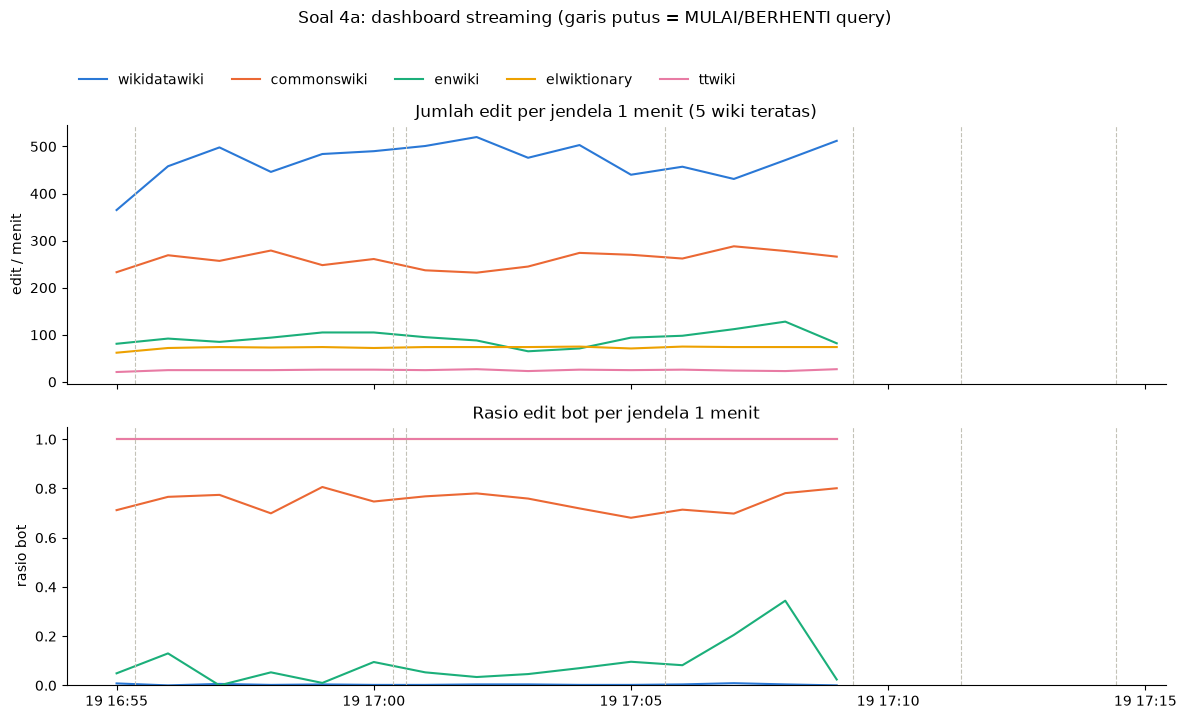

CSV dan PNG tersimpan di C:\BigData\notebooks\laporan_soal4


In [11]:
# ===== SEL 10: Dashboard =====
g = gabung_jendela()
n_uji = sum(1 for k in jendela if k[2] == "uji_terlambat")
print(f"Rekaman jendela: {len(jendela):,} ({n_uji} uji_terlambat) -> gabungan {len(g):,} baris (jendela x wiki)")
if g.empty:
    raise RuntimeError("Belum ada jendela wiki asli di Master; periksa keluaran Sel 5 Worker ('[batch N] ... terkirim').")
g.to_csv(LAPORAN_DIR / "4a_jendela_gabungan.csv", index=False)
g["waktu"] = pd.to_datetime(g["mulai"])
top = g.groupby("wiki")["n_edit"].sum().nlargest(5).index.tolist()
WARNA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
rentang = pd.date_range(g["waktu"].min(), g["waktu"].max(), freq="min")

fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for w, c in zip(top, WARNA):
    s = g[g["wiki"] == w].set_index("waktu").reindex(rentang)
    axs[0].plot(s.index, s["n_edit"], color=c, lw=1.5, label=w)
    axs[1].plot(s.index, s["rasio_bot"], color=c, lw=1.5, label=w)
axs[0].set(ylabel="edit / menit", title="Jumlah edit per jendela 1 menit (5 wiki teratas)")
axs[1].set(ylabel="rasio bot", ylim=(0, 1.05), title="Rasio edit bot per jendela 1 menit")
axs[0].legend(ncol=5, loc="upper left", bbox_to_anchor=(0, 1.25), frameon=False)
for t in LOG_SKENARIO:
    if t["aksi"] in ("MULAI", "BERHENTI") and t["untuk"] == "semua":
        for ax in axs:
            ax.axvline(pd.Timestamp(t["waktu"], unit="s", tz="UTC").tz_convert(ZONA).tz_localize(None),
                       color="#c3c2b7", lw=0.8, ls="--")
fig.suptitle("Soal 4a: dashboard streaming (garis putus = MULAI/BERHENTI query)", y=1.02)
fig.tight_layout(); fig.savefig(LAPORAN_DIR / "4a_dashboard.png", dpi=130, bbox_inches="tight"); plt.show(); plt.close(fig)
pd.DataFrame(LOG_SKENARIO).to_csv(LAPORAN_DIR / "4_log_skenario.csv", index=False)
print("CSV dan PNG tersimpan di", LAPORAN_DIR.resolve())